# CV Task 1 — completed notebook (Tasks 1–17)

Complete task cells for Sessions 1 and 2, including the optional camera/video tasks.
Each original question is retained, followed by its code and step-by-step English explanation.
Run cells top-to-bottom with Shift+Enter. The image loader and display helper are
defined in Task 1; no separate helper notebook is required.

Keep demo_image.png beside this file, or set IMAGE_PATH in Task 1 to your image.
Normal image exercises use uint8 BGR input. Camera/video examples are opt-in via
RUN_CAMERA/RUN_VIDEO; their functions are fully implemented. Desktop OpenCV is
needed for native camera windows. No packages are installed by these cells.


# Computer Vision Assignments: Sessions 1 & 2

This notebook contains tasks and assignments based on Sessions 1 and 2. You are required to implement the functions and complete the exercises as described. Use OpenCV and other necessary libraries like NumPy and Matplotlib.

**Instructions:**
- Complete each task in the provided code cells.
- Test your implementations with sample images (e.g., download test images [here](https://sipi.usc.edu/database/database.php?volume=misc) or [here](https://www.hlevkin.com/hlevkin/06testimages.htm) or use your own test images).
- Include comments in your code for clarity.
- Display results using cv2.imshow() or Matplotlib where appropriate.
- Submit the completed notebook along with any output images or explanations on [our google drive for the CV sessions](https://drive.google.com/drive/folders/1IjVhJmAXxNQTGT-ybJ-yc5smYtR5v8CO?usp=sharing) **upload your files in a new folder under your name**

## Session 1: Basic Image Operations (Reading, Resizing, Cropping, Rotating)

### Task 1: Read and Display an Image
Read an image from a file and display it in both BGR and grayscale formats. Handle errors if the image cannot be read.

Loaded: demo_image.png
Shape: (384, 512, 3) dtype: uint8


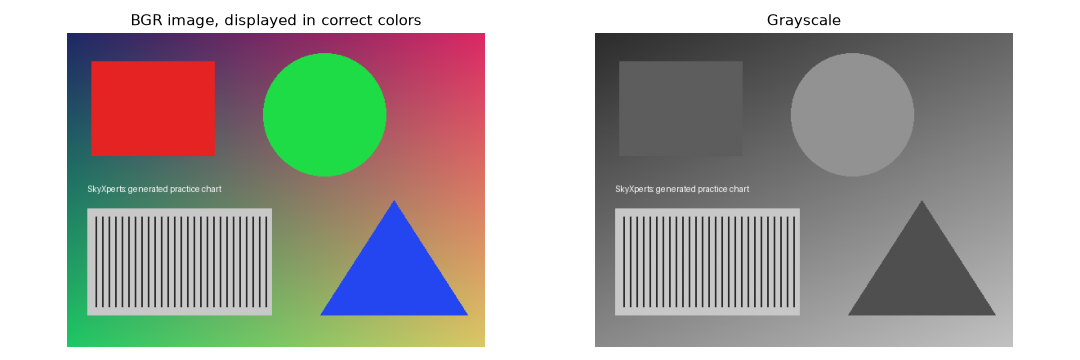

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter

# Keep this path for the included practice chart, or replace it with your photo.
IMAGE_PATH = Path('demo_image.png')
if not IMAGE_PATH.is_file() and str(IMAGE_PATH) == 'demo_image.png':
    IMAGE_PATH = Path('output/skyxperts_session2/demo_image.png')

img = cv.imread(str(IMAGE_PATH), cv.IMREAD_COLOR)
if img is None:
    raise FileNotFoundError(f'Cannot read image: {IMAGE_PATH.resolve()}')

def show_images(results, columns=2):
    rows = (len(results) + columns - 1) // columns
    plt.figure(figsize=(6 * columns, 4 * rows))
    for i, (title, image) in enumerate(results):
        plt.subplot(rows, columns, i + 1)
        if image.ndim == 2:
            plt.imshow(image, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

print('Loaded:', IMAGE_PATH)
print('Shape:', img.shape, 'dtype:', img.dtype)


# Task 1: OpenCV stores the loaded color image in BGR order.
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
show_images([('BGR image, displayed in correct colors', img), ('Grayscale', gray)])


**Step 1:** Import OpenCV as cv, NumPy as np and Matplotlib as plt. The included demo image makes the notebook runnable without a placeholder filename. Set IMAGE_PATH to your own image if desired.

**Step 2:** imread reads BGR data. A failed read gives None, which is checked before using the image.

**Step 3:** Define show_images before using it. It converts BGR to RGB for plotting and handles grayscale separately. Grayscale stores one intensity value instead of three color channels.

**Step 4:** The helper is reused by later cells, so run this cell after Restart Kernel. Do not overwrite img with RGB later.


### Task 2: Resize Image with Aspect Ratio Preservation
Implement resizing while preserving aspect ratio. Downscale to 60% and upscale to 200%. Compare shapes and display originals vs resized.

Original: (384, 512, 3)
60%: (230, 307, 3)
200%: (768, 1024, 3)


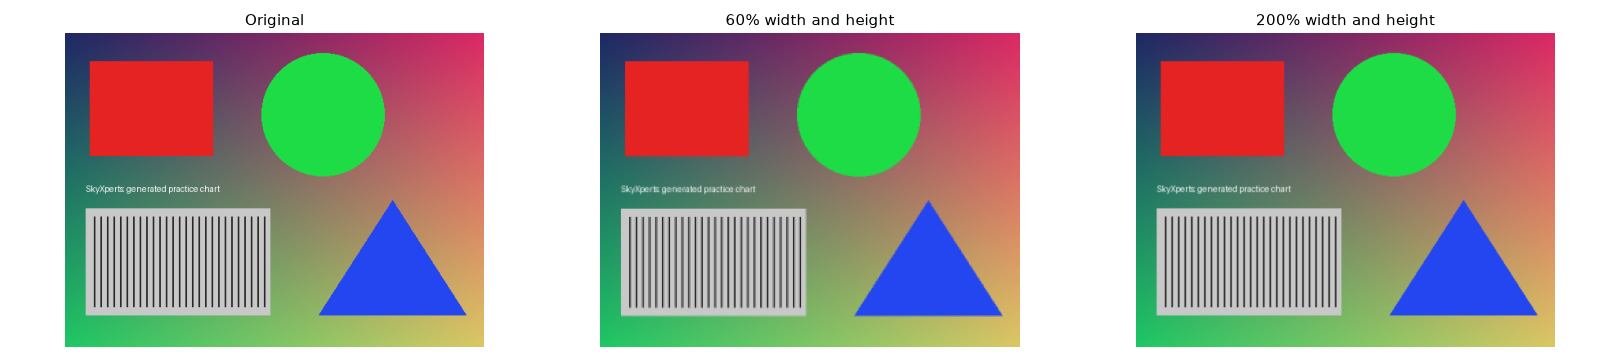

In [2]:
# Equal scale factors preserve the aspect ratio, subject to pixel rounding.
downscaled = cv.resize(img, None, fx=0.6, fy=0.6, interpolation=cv.INTER_AREA)
upscaled = cv.resize(img, None, fx=2.0, fy=2.0, interpolation=cv.INTER_LINEAR)
print('Original:', img.shape)
print('60%:', downscaled.shape)
print('200%:', upscaled.shape)
show_images([('Original', img), ('60% width and height', downscaled),
             ('200% width and height', upscaled)], columns=3)


**Step 1:** Resize from the original image each time. fx and fy are equal, so horizontal and vertical scale match.

**Step 2:** A 500x300 image becomes approximately 300x180 at 60%, and 1000x600 at 200%. Actual dimensions are rounded to integer pixels.

**Step 3:** Printed shapes are (height,width,channels). Equal-size plotting panels can hide the physical resolution difference. Enlargement does not invent genuine detail.


### Task 3: Resize Without Preserving Aspect Ratio
Resize only width to 100 pixels, only height to 200 pixels, and both to (200, 200). Display and discuss distortions.

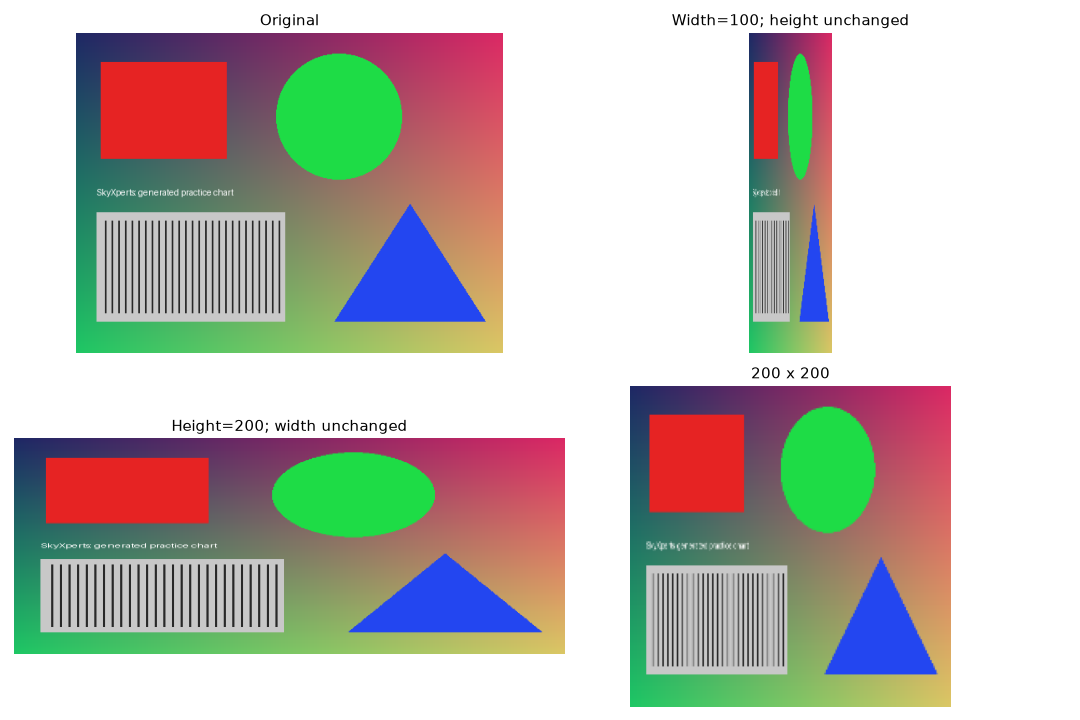

In [3]:
h, w = img.shape[:2]
width_only = cv.resize(img, (100, h))
height_only = cv.resize(img, (w, 200))
square = cv.resize(img, (200, 200))
show_images([('Original', img), ('Width=100; height unchanged', width_only),
             ('Height=200; width unchanged', height_only), ('200 x 200', square)])


**Step 1:** OpenCV size arguments are (width,height), unlike image.shape.

**Step 2:** (100,h) changes width while preserving the original height. (w,200) changes only height.

**Step 3:** (200,200) forces a square. Changing width and height by different proportions distorts shapes: circles can become ellipses. A square output preserves proportions only if the input was square.


### Task 4: Resize Using Scale Factors (fx, fy)
Scale up by 1.2 in both directions and down by 0.6. Use different interpolations (INTER_LINEAR, INTER_NEAREST) and compare quality.

Enlarged: (461, 614, 3) Reduced: (230, 307, 3)


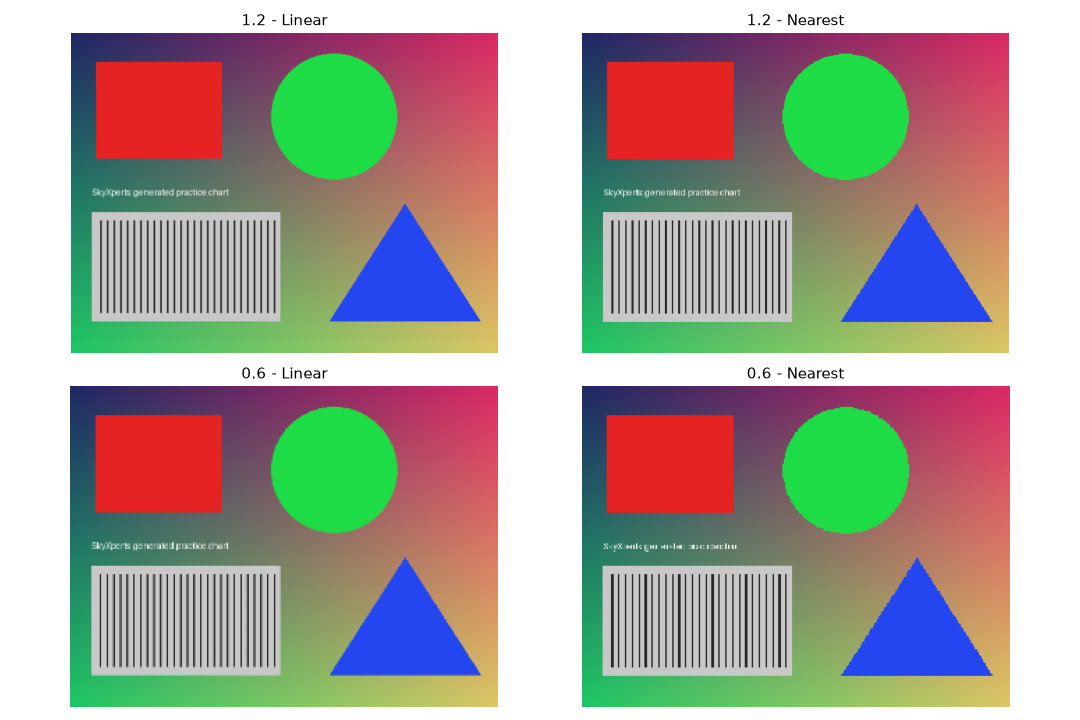

In [4]:
up_linear = cv.resize(img, None, fx=1.2, fy=1.2, interpolation=cv.INTER_LINEAR)
up_nearest = cv.resize(img, None, fx=1.2, fy=1.2, interpolation=cv.INTER_NEAREST)
down_linear = cv.resize(img, None, fx=0.6, fy=0.6, interpolation=cv.INTER_LINEAR)
down_nearest = cv.resize(img, None, fx=0.6, fy=0.6, interpolation=cv.INTER_NEAREST)
show_images([('1.2 - Linear', up_linear), ('1.2 - Nearest', up_nearest),
             ('0.6 - Linear', down_linear), ('0.6 - Nearest', down_nearest)])
print('Enlarged:', up_linear.shape, 'Reduced:', down_linear.shape)


**Step 1:** 1.2 means 20% larger per dimension; 0.6 means 40% smaller per dimension.

**Step 2:** Nearest copies a source value, often creating jagged edges. Linear blends nearby values, usually giving smoother but sometimes softer edges.

**Step 3:** Apply both methods to the same original for a fair comparison. Resizing is resampling; downscaling loses information and may introduce aliasing.


### Task 5: Cropping an Image
Crop a region (e.g., [20:200, 50:200]) from the image. Display original and cropped.

Original shape: (384, 512, 3)
Cropped shape: (180, 150, 3)


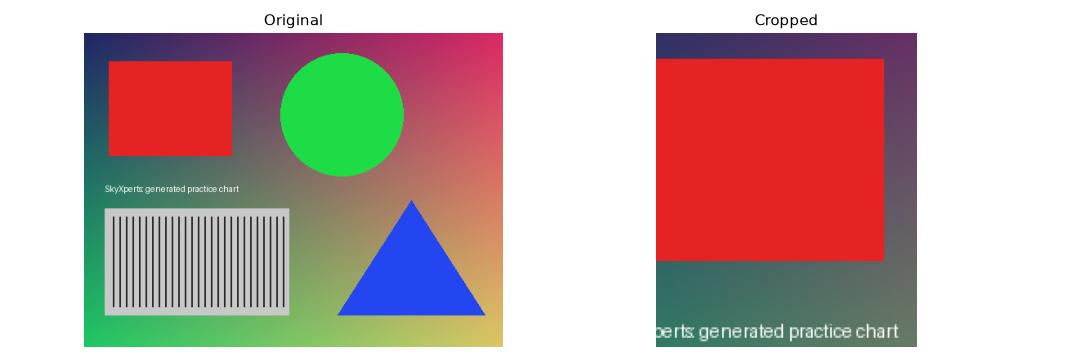

In [5]:
cropped = img[20:200, 50:200]
if cropped.size == 0:
    raise ValueError('Choose crop coordinates inside your image.')
print('Original shape:', img.shape)
print('Cropped shape:', cropped.shape)
show_images([('Original', img), ('Cropped', cropped)])


**Step 1:** img[20:200,50:200] selects rows 20..199 and columns 50..199. Array indexing uses [y,x], not [x,y].

**Step 2:** With an image large enough, the crop is 180 pixels high and 150 wide. Stops beyond image bounds are clipped automatically; an out-of-range start can make the crop empty.

**Step 3:** Cropping selects part of the existing image; it does not shrink all its contents. A basic slice shares data with the original. Add .copy() before modifying it independently.


### Task 6: Advanced Cropping - Patch Image into Blocks
Divide the image into 4 equal blocks (2x2 grid) by cropping. Display each block separately and then stitch them back using NumPy concatenation to verify.

Excluded rows: 0 Excluded columns: 0
Identical: True


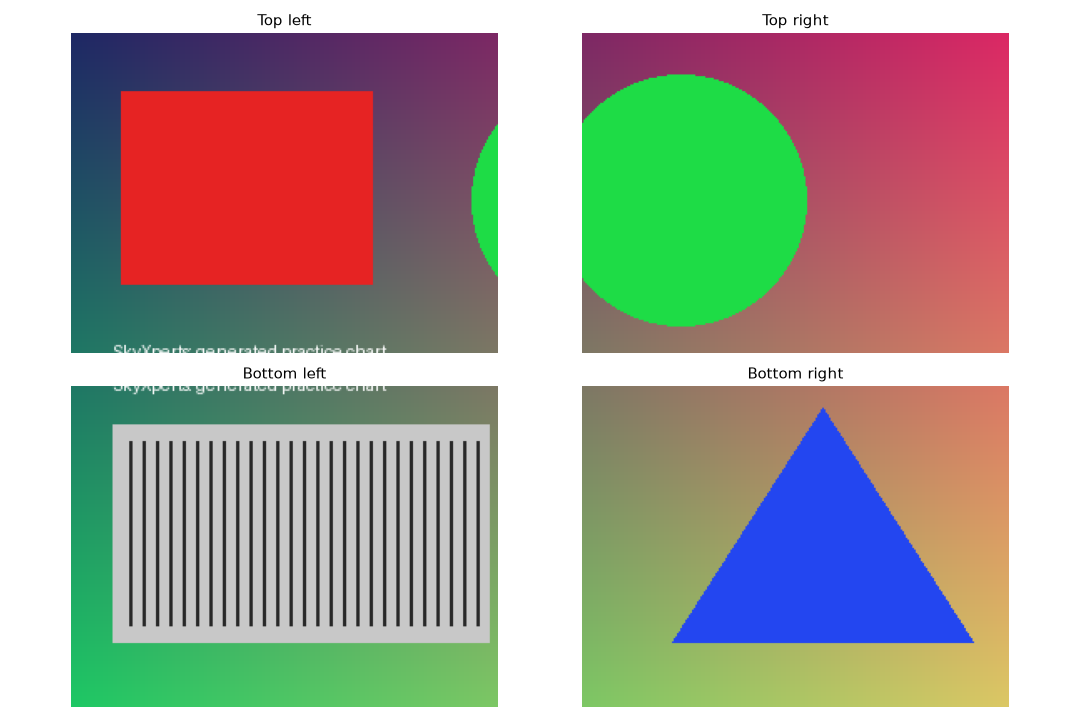

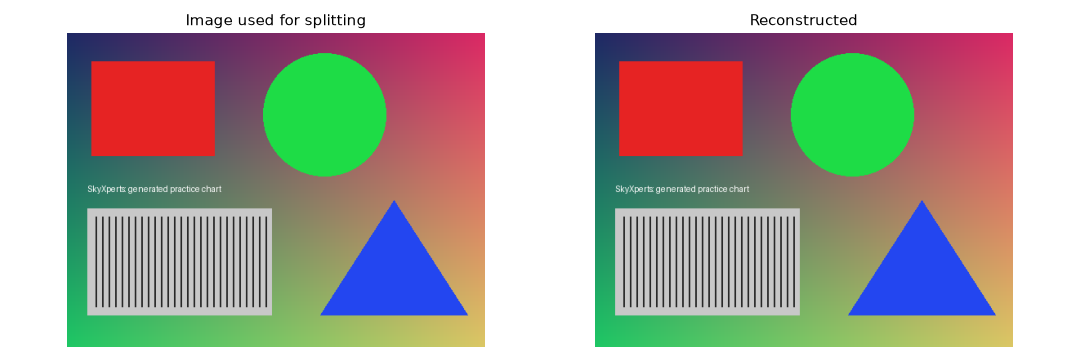

In [6]:
h, w = img.shape[:2]
if min(h, w) < 2:
    raise ValueError('The image must be at least 2 x 2 pixels.')
even_h, even_w = h - h % 2, w - w % 2
base = img[:even_h, :even_w]
print('Excluded rows:', h - even_h, 'Excluded columns:', w - even_w)
mid_h, mid_w = even_h // 2, even_w // 2
top_left = base[:mid_h, :mid_w]
top_right = base[:mid_h, mid_w:]
bottom_left = base[mid_h:, :mid_w]
bottom_right = base[mid_h:, mid_w:]
show_images([('Top left', top_left), ('Top right', top_right),
             ('Bottom left', bottom_left), ('Bottom right', bottom_right)])
top = np.hstack((top_left, top_right))
bottom = np.hstack((bottom_left, bottom_right))
reconstructed = np.vstack((top, bottom))
show_images([('Image used for splitting', base), ('Reconstructed', reconstructed)])
print('Identical:', np.array_equal(base, reconstructed))


**Step 1:** Four exactly equal integer-pixel blocks require even height and width. For odd dimensions, this example excludes only the final row/column in base; img is unchanged. The excluded counts are printed.

**Step 2:** // finds integer midpoints. :mid means start to just before the midpoint; mid: means midpoint to the end.

**Step 3:** hstack joins left and right; vstack joins upper and lower. array_equal compares against base, the actual split input, and should return True.


### Task 7: Rotating an Image
Rotate the image by 45°, 90°, and 180° using getRotationMatrix2D and warpAffine. Display all rotations.

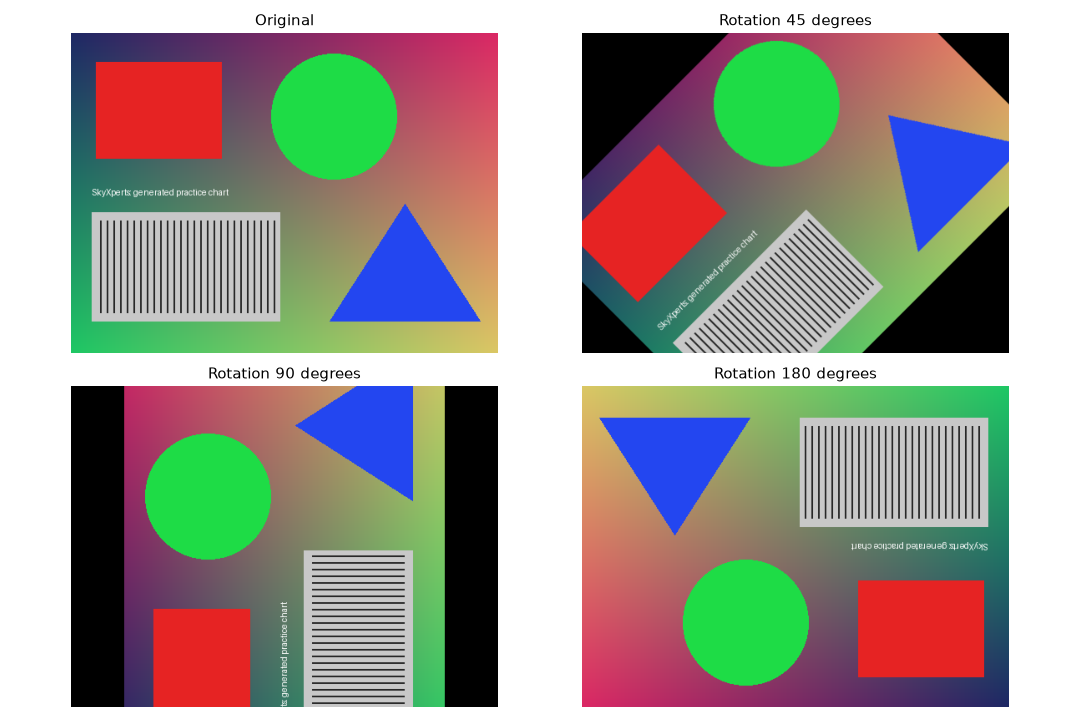

In [7]:
h, w = img.shape[:2]
center = ((w - 1) / 2, (h - 1) / 2)
rotations = [('Original', img)]
for angle in [45, 90, 180]:
    matrix = cv.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv.warpAffine(img, matrix, (w, h), flags=cv.INTER_LINEAR,
                            borderMode=cv.BORDER_CONSTANT, borderValue=(0, 0, 0))
    rotations.append((f'Rotation {angle} degrees', rotated))
show_images(rotations)


**Step 1:** The center is ((w-1)/2,(h-1)/2) because pixel-center coordinates start at zero.

**Step 2:** getRotationMatrix2D calculates a 2x3 affine matrix. A positive angle rotates counterclockwise; scale 1.0 leaves the content scale unchanged.

**Step 3:** warpAffine executes the transform. (w,h) fixes the output canvas; outside-source locations become black. Rotated corners may be clipped, particularly at 45 degrees or at 90 degrees for a rectangular source.


### Task 8: Rotate with Scaling
Rotate by 45° and scale by 0.5 in **one** operation. Compare with separate resize and rotate.

Mean absolute difference: 1.1536916097005208


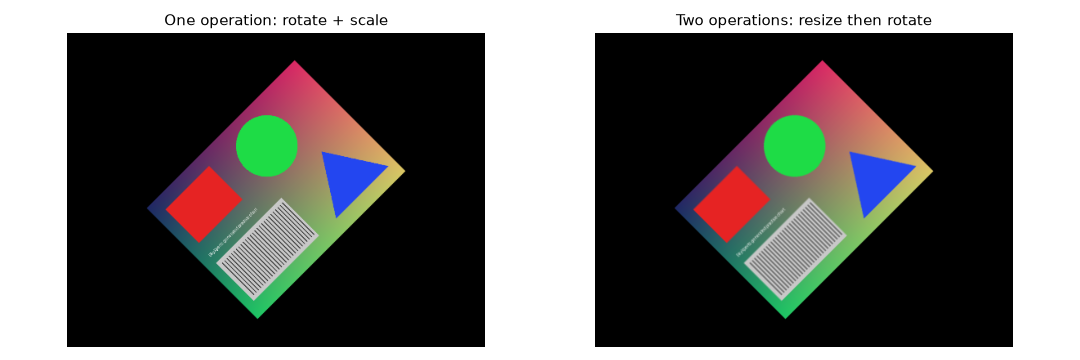

In [8]:
h, w = img.shape[:2]
if min(h, w) < 2:
    raise ValueError('The image must be at least 2 x 2 pixels.')
# Even dimensions make resizing by 0.5 exact in both directions.
source = img[:h - h % 2, :w - w % 2]
h, w = source.shape[:2]
center = ((w - 1) / 2, (h - 1) / 2)
combined_matrix = cv.getRotationMatrix2D(center, 45, 0.5)
combined = cv.warpAffine(source, combined_matrix, (w, h), flags=cv.INTER_LINEAR)
small = cv.resize(source, (w // 2, h // 2), interpolation=cv.INTER_LINEAR)
small_h, small_w = small.shape[:2]
small_center = ((small_w - 1) / 2, (small_h - 1) / 2)
separate_matrix = cv.getRotationMatrix2D(small_center, 45, 1.0)
separate_matrix[0, 2] += center[0] - small_center[0]
separate_matrix[1, 2] += center[1] - small_center[1]
separate = cv.warpAffine(small, separate_matrix, (w, h), flags=cv.INTER_LINEAR)
show_images([('One operation: rotate + scale', combined),
             ('Two operations: resize then rotate', separate)])
print('Mean absolute difference:', float(cv.absdiff(combined, separate).mean()))


**Step 1:** Use even dimensions so a half-size result needs no dimension rounding. The original img is not modified.

**Step 2:** The first transform combines 45-degree rotation and scale 0.5. Output canvas dimensions remain (w,h), while the content shrinks.

**Step 3:** The second path resizes first, then rotates with scale 1.0. The matrix's last column stores translation. Adjust it by the difference between the large and small centers so both results align.

**Step 4:** One resampling versus two can produce different pixel values. Neither path guarantees best quality on every image, and fixed canvas bounds can clip very elongated inputs.


## Session 2: Image Acquisition, Formats, Color Spaces, Enhancement, and Filtering

### Task 9: Read Image in Different Color Spaces
Read an image in BGR, convert to RGB (for Matplotlib), HSV, LAB and Grayscale. Display all.

BGR pixel: [100  40  30]
RGB pixel: [ 30  40 100]
Grayscale shape: (384, 512)


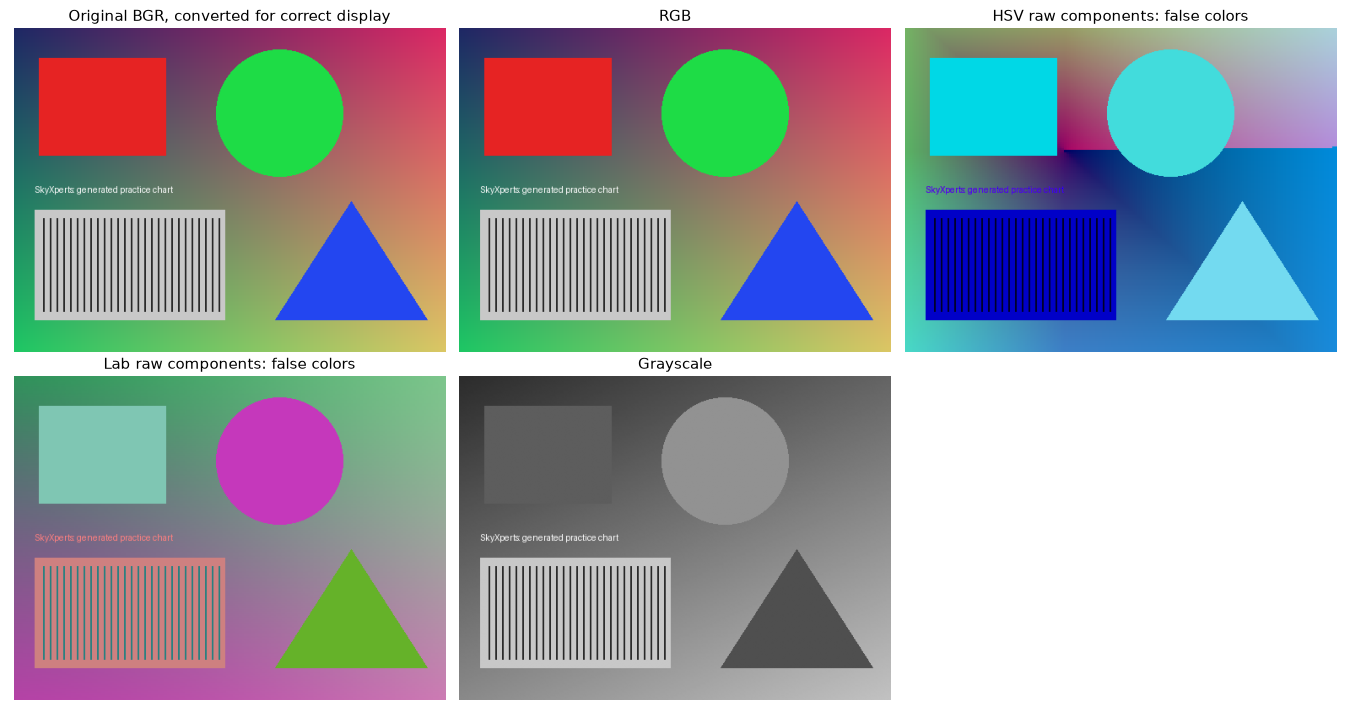

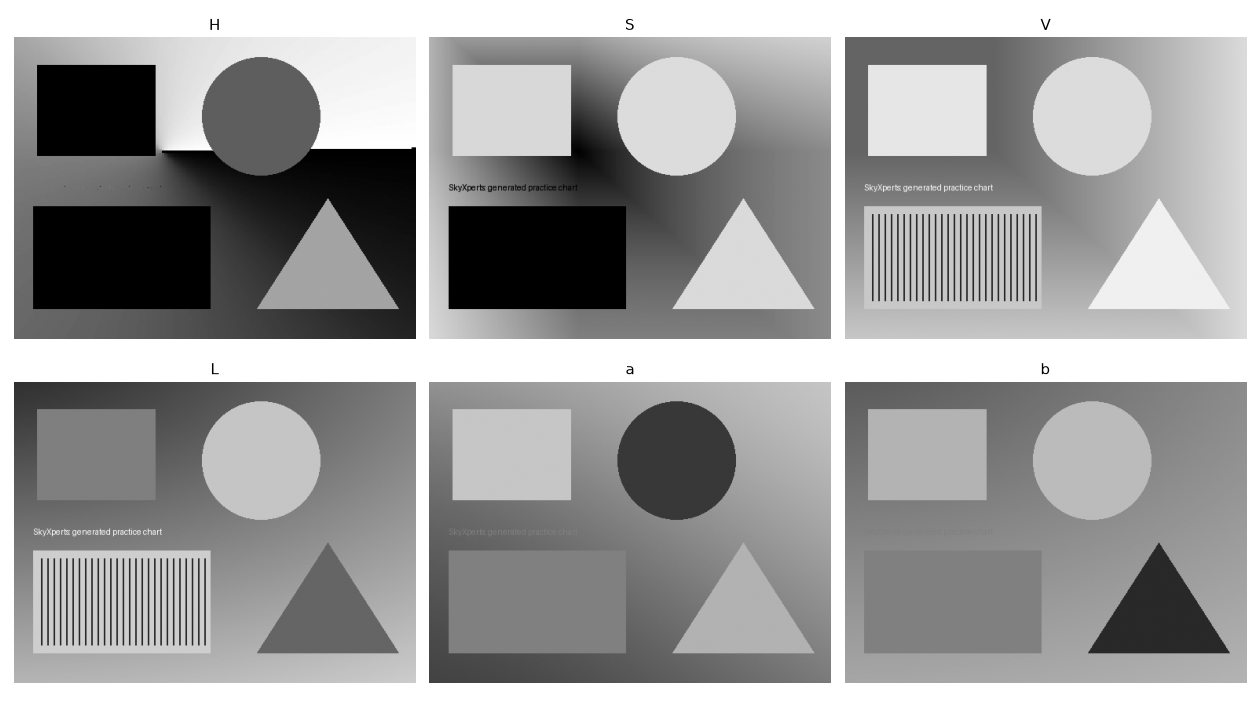

In [9]:
rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Matplotlib treats any three-channel array as RGB.
panels = [
    ('Original BGR, converted for correct display', rgb),
    ('RGB', rgb),
    ('HSV raw components: false colors', hsv),
    ('Lab raw components: false colors', lab),
    ('Grayscale', gray),
]
plt.figure(figsize=(15, 8))
for i, (title, image) in enumerate(panels):
    plt.subplot(2, 3, i + 1)
    if image.ndim == 2:
        plt.imshow(image, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(image)
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

# Each channel is a scalar field, so display it separately in grayscale.
channels = [('H', hsv[:, :, 0], 179), ('S', hsv[:, :, 1], 255),
            ('V', hsv[:, :, 2], 255), ('L', lab[:, :, 0], 255),
            ('a', lab[:, :, 1], 255), ('b', lab[:, :, 2], 255)]
plt.figure(figsize=(14, 8))
for i, (name, channel, maximum) in enumerate(channels):
    plt.subplot(2, 3, i + 1)
    plt.imshow(channel, cmap='gray', vmin=0, vmax=maximum)
    plt.title(name)
    plt.axis('off')
plt.tight_layout()
plt.show()

print('BGR pixel:', img[0, 0])
print('RGB pixel:', rgb[0, 0])
print('Grayscale shape:', gray.shape)


**Step 1 — Convert:** cvtColor receives the source array and an explicit conversion flag.
RGB swaps the red and blue channel order. HSV and Lab change the representation.
Grayscale combines color information into one intensity channel; it is not just one
of the original channels. A common approximation is 0.114B + 0.587G + 0.299R.

**Step 2 — Display:** The first two pictures should look the same: correctly displayed
BGR and RGB describe the same colors. Raw HSV/Lab will look unusual because the plot
interprets their components as RGB. That is a false-color component display, not
the natural appearance of those spaces. Convert HSV2RGB/Lab2RGB to recover natural
colors, accepting conversion/quantization losses.

**Step 3 — Inspect components:** hsv[:, :, 0] means all rows, all columns, channel 0.
The channel plots let you see the actual component values without pretending they
are red, green and blue. Single-channel displays lose the original color context.

**Expected observation:** Color arrays keep shape (H,W,3); gray becomes (H,W).
A red BGR pixel [0,0,255] becomes RGB [255,0,0].


### Task 10: Image Sharpening
Apply cv2.blur() with a 5x5 kernel, then use cv2.filter2D() with sharpening kernels of varying strengths (e.g., [[0, -1, 0], [-1, 5, -1], [0, -1, 0]] and [[0, -2, 0], [-2, 9, -2], [0, -2, 0]]).
Compare between original and sharpened image after blurring.

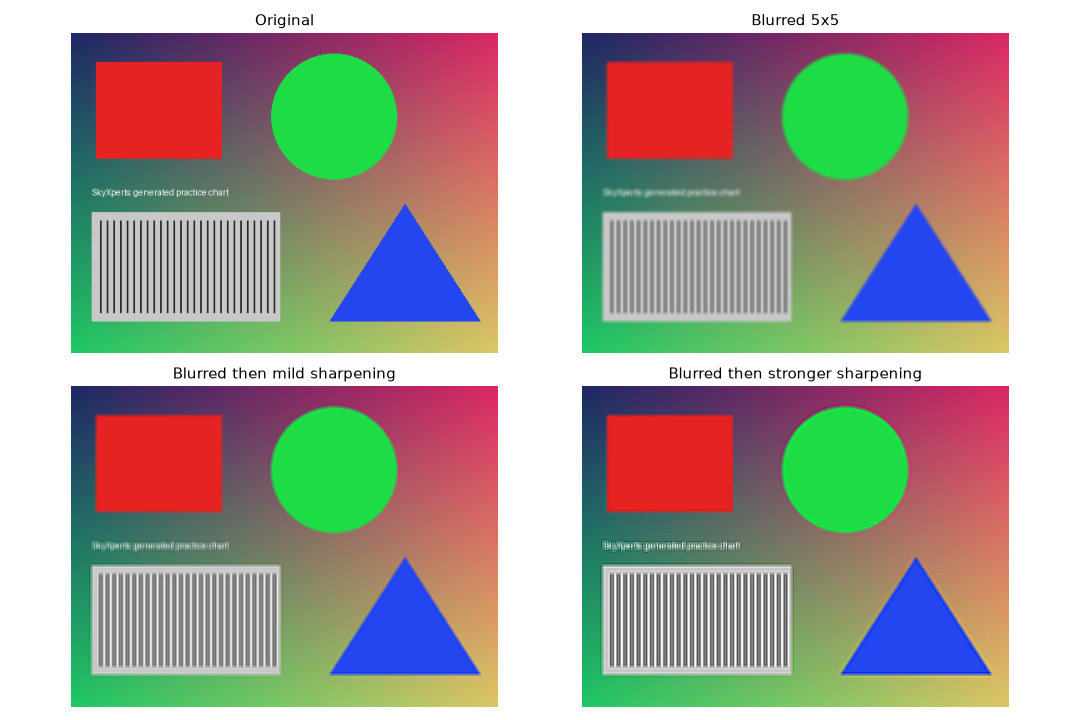

In [10]:
blurred = cv.blur(img, (5, 5))

kernel_mild = np.array([[0, -1, 0],
                        [-1, 5, -1],
                        [0, -1, 0]], dtype=np.float32)
kernel_strong = np.array([[0, -2, 0],
                          [-2, 9, -2],
                          [0, -2, 0]], dtype=np.float32)

sharp_mild = cv.filter2D(blurred, -1, kernel_mild)
sharp_strong = cv.filter2D(blurred, -1, kernel_strong)

show_images([('Original', img), ('Blurred 5x5', blurred),
             ('Blurred then mild sharpening', sharp_mild),
             ('Blurred then stronger sharpening', sharp_strong)])


**Step 1 — Blur:** Each output value becomes the average of a 5×5 neighborhood
(25 values). Averaging reduces rapid variations and also softens edges.

**Step 2 — Build kernels:** For the mild kernel, the response is
5×center - top - bottom - left - right. If the center is 100 and all four
neighbors are 90, the response is 140. The strong kernel gives 180.
Both kernels sum to 1, so a constant patch remains constant.

**Step 3 — Apply to blurred:** We pass blurred, not img, to follow the question.
`ddepth=-1` keeps the source output depth. With uint8, values outside 0..255
are saturated. Stronger sharpening can create halos and clipping.

**Expected observation:** The stronger result emphasizes boundaries more. Neither
kernel reconstructs all original detail lost in the averaging operation.
Technical note: filter2D implements correlation rather than flipping the kernel;
these symmetric kernels give the same result either way.


### Task 11: Add Salt and Pepper Noise to Image
Implement a function to add salt and pepper noise to an image. Control noise density (e.g., 0.05).

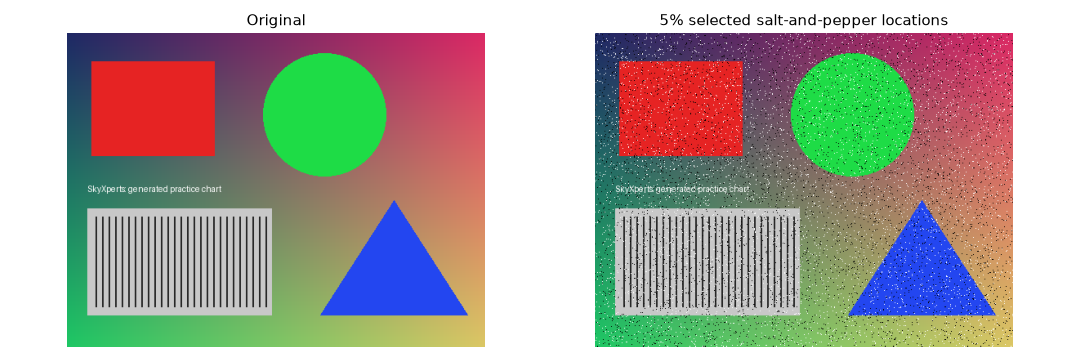

In [11]:
def add_salt_pepper_noise(image, density=0.05, seed=None):
    if image.dtype != np.uint8 or image.ndim not in (2, 3) or image.size == 0:
        raise ValueError('Use a nonempty uint8 grayscale or color image.')
    if not np.isfinite(density) or not 0 <= density <= 1:
        raise ValueError('density must be between 0 and 1.')

    noisy = image.copy()
    height, width = image.shape[:2]
    count = round(density * height * width)
    rng = np.random.default_rng(seed)

    # Choose DISTINCT pixel locations, not separate color-channel entries.
    locations = rng.choice(height * width, size=count, replace=False)
    salt_count = count // 2
    salt_y, salt_x = np.divmod(locations[:salt_count], width)
    pepper_y, pepper_x = np.divmod(locations[salt_count:], width)

    noisy[salt_y, salt_x] = 255
    noisy[pepper_y, pepper_x] = 0
    return noisy

noisy = add_salt_pepper_noise(img, density=0.05, seed=42)
show_images([('Original', img), ('5% selected salt-and-pepper locations', noisy)])


**Step 1 — Copy:** Editing noisy must not damage the clean reference img.

**Step 2 — Count:** On a 100×100 image, density=0.05 selects 500 pixel locations.
About half become white (salt), half black (pepper). The fraction refers to pixel
positions, not 5% of each RGB/BGR channel independently.

**Step 3 — Select:** replace=False prevents duplicate locations, including a salt
pixel later being overwritten with pepper. divmod converts a flat index into
(row, column). For width=100, flat index 235 becomes row 2, column 35.

**Step 4 — Set:** Assignment of 255 or 0 broadcasts across all color channels.
seed=42 makes the same experiment repeatable. Selected locations can already
have the assigned color, so the fraction visibly changed can be less than density.


### Task 12: Remove Salt and Pepper Noise Using Median Filter
Apply cv.medianBlur() to a noisy image. Experiment with kernel sizes (3,5,7) and compare results.

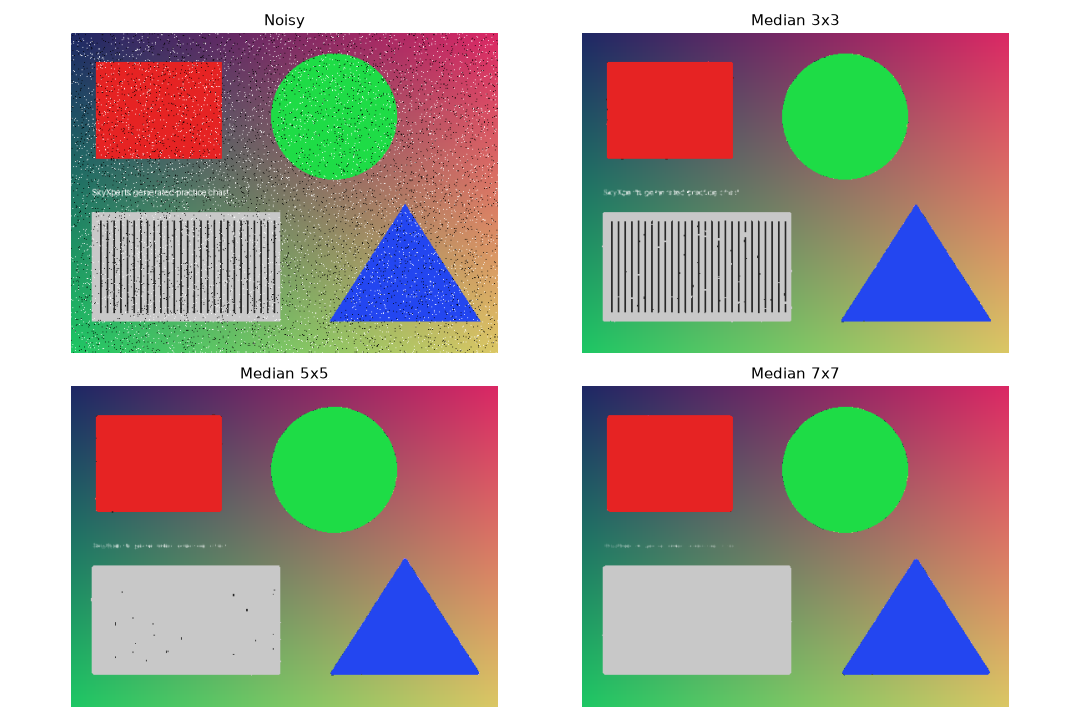

In [12]:
median3 = cv.medianBlur(noisy, 3)
median5 = cv.medianBlur(noisy, 5)
median7 = cv.medianBlur(noisy, 7)

show_images([('Noisy', noisy), ('Median 3x3', median3),
             ('Median 5x5', median5), ('Median 7x7', median7)])


**Step 1 — Start from the SAME noisy image:** Do not repeatedly filter the previous
result when comparing kernel sizes; that would compare different pipelines.

**Step 2 — Find a middle value:** In a 3×3 neighborhood, sort nine values and take
the fifth. In [10,10,11,11,12,12,13,13,255], the median is 12, resisting the impulse.

**Step 3 — Compare sizes:** A bigger neighborhood can handle more impulses but may
remove thin lines, textures and small objects. Larger is not automatically better.
For this uint8 exercise, 3,5,7 are valid odd sizes. OpenCV treats color channels
separately and uses replicated borders internally.


### Task 13: Implement Adaptive Median Filter
Write a custom function for adaptive median filtering. It should dynamically increase window size until noise is removed or max size is reached. Apply to a noisy image and compare with standard median.

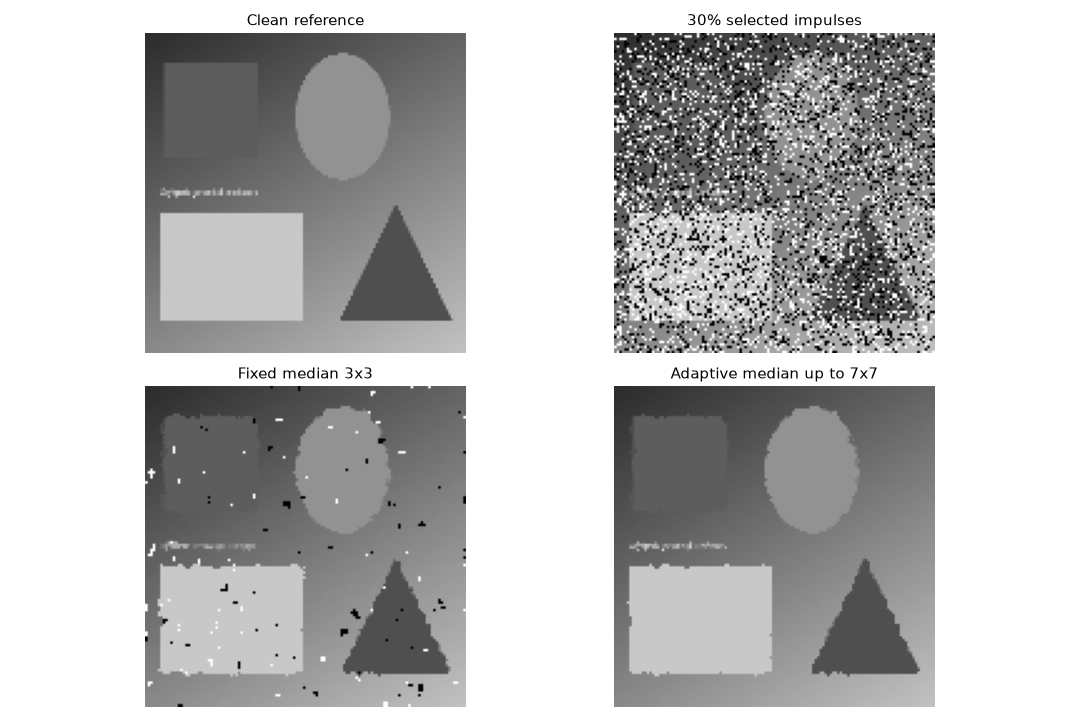

In [13]:
def adaptive_median_filter(image, max_size=7):
    if image.dtype != np.uint8 or image.ndim not in (2, 3) or image.size == 0:
        raise ValueError('Use a nonempty uint8 grayscale or color image.')
    if not isinstance(max_size, (int, np.integer)) or max_size < 3 or max_size % 2 == 0:
        raise ValueError('max_size must be an odd integer of at least 3.')
    if image.ndim == 3:
        return np.stack([adaptive_median_filter(image[:, :, c], max_size)
                         for c in range(image.shape[2])], axis=2)

    height, width = image.shape
    padding = max_size // 2
    padded = np.pad(image, padding, mode='edge')
    result = np.empty_like(image)

    for y in range(height):
        for x in range(width):
            cy, cx = y + padding, x + padding
            current = int(padded[cy, cx])
            for size in range(3, max_size + 1, 2):
                radius = size // 2
                window = padded[cy-radius:cy+radius+1,
                                cx-radius:cx+radius+1]
                minimum = int(window.min())
                maximum = int(window.max())
                median = int(np.median(window))

                # Stage A: is the local median strictly between the extremes?
                if minimum < median < maximum:
                    # Stage B: keep a non-extreme current value, else use median.
                    result[y, x] = current if minimum < current < maximum else median
                    break
                if size == max_size:
                    result[y, x] = median
    return result

# Small teaching example: the clear Python loops are slower than OpenCV.
sample_gray = cv.cvtColor(cv.resize(img, (128, 128)), cv.COLOR_BGR2GRAY)
adaptive_noisy = add_salt_pepper_noise(sample_gray, density=0.30, seed=7)
standard = cv.medianBlur(adaptive_noisy, 3)
adaptive = adaptive_median_filter(adaptive_noisy, max_size=7)

show_images([('Clean reference', sample_gray), ('30% selected impulses', adaptive_noisy),
             ('Fixed median 3x3', standard), ('Adaptive median up to 7x7', adaptive)])


**Step 1 — Pad:** edge padding repeats boundary values so every pixel has a full window.

**Step 2 — Visit each pixel:** y is its row; x its column. Start with size=3.
Measure the neighborhood minimum, median and maximum.

**Step 3 — Stage A:** If min < median < max, the median is a usable non-extreme
candidate. Otherwise enlarge to 5×5, then 7×7. This is the adaptive part.

**Step 4 — Stage B:** If min < current < max, keep the current pixel; otherwise
replace it with the median. A failed Stage A at maximum size returns that window's
median. For [0,0,0,0,0,0,100,110,255], the 3×3 median is 0, so try a larger window.

**Limits:** Extremeness is a heuristic, not proof of corruption: valid black/white
features can change. If impulses dominate every allowed window, recovery can fail.
Applying channels separately is not a vector-color median and can alter color.
The algorithm is nonlinear; results depend on max_size and border handling.
The source is never updated in place, avoiding scan-order dependence.


### Task 14: Implement Bilateral Filter Function
Write a Python function to perform bilateral filtering on an image. Use Gaussian weights for both spatial and intensity. Parameters: diameter, sigma_color, sigma_space. Compare with cv.bilateralFilter().

Mean absolute difference: 0.0
Maximum absolute difference: 0


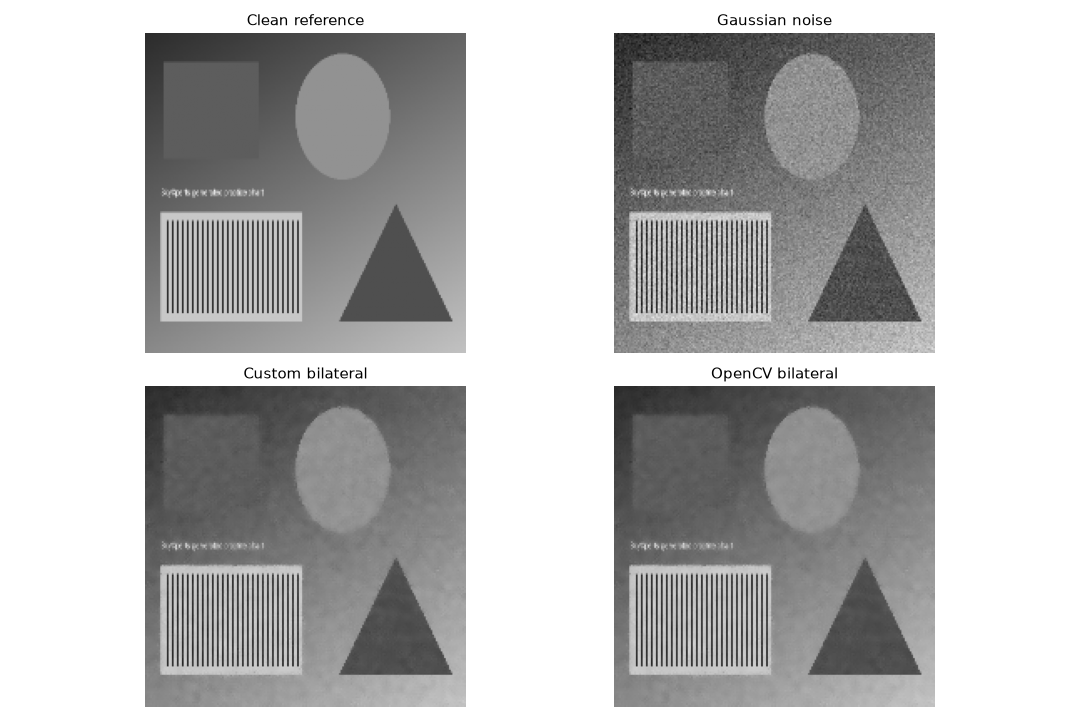

In [14]:
def custom_bilateral_filter(image, diameter, sigma_color, sigma_space):
    # Grayscale keeps the intensity-distance definition unambiguous.
    if image.ndim != 2 or image.dtype != np.uint8 or image.size == 0:
        raise ValueError('Use a nonempty uint8 grayscale image.')
    if not isinstance(diameter, (int, np.integer)) or diameter < 1 or diameter % 2 == 0:
        raise ValueError('diameter must be a positive odd integer.')
    if not np.isfinite(sigma_color) or not np.isfinite(sigma_space) or sigma_color <= 0 or sigma_space <= 0:
        raise ValueError('Both sigmas must be finite and positive.')

    radius = diameter // 2
    center = image.astype(np.float64)
    height, width = center.shape
    padded = np.pad(center, radius, mode='reflect')
    numerator = np.zeros_like(center)
    denominator = np.zeros_like(center)

    # Iterate offsets, processing all image pixels at once with NumPy.
    for dy in range(-radius, radius + 1):
        for dx in range(-radius, radius + 1):
            distance_squared = dx * dx + dy * dy
            if distance_squared > radius * radius:
                continue  # Circular support, matching OpenCV's neighborhood.
            neighbor = padded[radius+dy:radius+dy+height,
                              radius+dx:radius+dx+width]
            spatial_weight = np.exp(-distance_squared / (2 * sigma_space**2))
            range_weight = np.exp(-((neighbor - center)**2) / (2 * sigma_color**2))
            weight = spatial_weight * range_weight
            numerator += weight * neighbor
            denominator += weight

    return np.clip(np.rint(numerator / denominator), 0, 255).astype(np.uint8)

bilateral_input = cv.cvtColor(cv.resize(img, (192, 192)), cv.COLOR_BGR2GRAY)
rng = np.random.default_rng(21)
gaussian_noisy = np.clip(bilateral_input.astype(np.float64)
                         + rng.normal(0, 12, bilateral_input.shape), 0, 255).astype(np.uint8)

custom = custom_bilateral_filter(gaussian_noisy, 7, 30, 3)
opencv = cv.bilateralFilter(gaussian_noisy, 7, 30, 3,
                           borderType=cv.BORDER_REFLECT_101)

show_images([('Clean reference', bilateral_input), ('Gaussian noise', gaussian_noisy),
             ('Custom bilateral', custom), ('OpenCV bilateral', opencv)])
difference = cv.absdiff(custom, opencv)
print('Mean absolute difference:', float(difference.mean()))
print('Maximum absolute difference:', int(difference.max()))


**Step 1 — Convert to float:** Subtracting uint8 values directly can wrap around.
Float arithmetic preserves negative differences and fractional weights.

**Step 2 — Distance weight:** exp(-(dx²+dy²)/(2*sigma_space²)) gives nearby pixels
more influence. A large sigma_space lets farther pixels contribute more, within
the chosen diameter.

**Step 3 — Intensity weight:** exp(-(neighbor-center)²/(2*sigma_color²)) suppresses
very different values. For sigma_color=20, differences 5 and 100 receive weights
about 0.969 and 0.0000037. So a dark pixel across a bright edge has little influence.

**Step 4 — Normalize:** Add weight×value and divide by total weight. The center has
weight 1, so the denominator is positive. A constant image stays constant.

**Comparison details:** Both functions use the same circular neighborhood and
reflected border convention. Float precision, rounding and optimized OpenCV
implementations can produce small differences; exact equality is not required.
This function deliberately accepts grayscale. Extending to color requires choosing
and documenting a vector distance; channel-by-channel filtering is a different rule.
Strong impulse noise may be preserved as an edge, so median is often more suitable.


### [BONUS] Task 15: Comprehensive Camera Task 
Combine: Live camera feed -> grayscale -> add noise -> remove with median -> sharpen. Display all stages in separate windows.

In [15]:
def process_frame(frame, rng):
    gray_frame = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    frame_seed = int(rng.integers(0, 2**32))
    noisy_frame = add_salt_pepper_noise(gray_frame, 0.05, seed=frame_seed)
    denoised_frame = cv.medianBlur(noisy_frame, 3)
    sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)
    final_frame = cv.filter2D(denoised_frame, -1, sharpen_kernel)
    return gray_frame, noisy_frame, denoised_frame, final_frame

def run_camera(camera_id=0):
    capture = cv.VideoCapture(camera_id)
    rng = np.random.default_rng(42)
    try:
        if not capture.isOpened():
            raise RuntimeError(f'Cannot open camera {camera_id}.')
        while True:
            ok, frame = capture.read()
            if not ok:
                break
            stages = process_frame(frame, rng)
            cv.imshow('Camera - original', frame)
            for name, stage in zip(('Gray', 'Noisy', 'Median', 'Sharpened'), stages):
                cv.imshow(name, stage)
            if cv.waitKey(1) & 0xFF == ord('q'):
                break
    finally:
        capture.release()
        cv.destroyAllWindows()

RUN_CAMERA = False  # Set True and run this cell locally when ready; press q to stop.
if RUN_CAMERA:
    run_camera(0)
else:
    print('Camera example ready. RUN_CAMERA=False: no camera opened.')


Camera example ready. RUN_CAMERA=False: no camera opened.


**Step 1:** Define process_frame once; camera and video reuse the same pipeline.
**Step 2:** read() returns a success flag and a BGR frame; check the flag first.
**Step 3:** Convert → add noise → median → sharpen, exactly in the question's order.
**Step 4:** Separate OpenCV windows show every stage. Click a video window and press q.
**Step 5:** finally releases the device and closes windows even after an exception.

Run this optional cell on your local Jupyter kernel with desktop OpenCV installed.
A remote/headless kernel cannot provide native windows or your local webcam.
The first-time device permission prompt must be handled on your computer.


### [BONUS]Task 16: Comprehensive Video Task
Similar to Task 18 but for a video file. Save the final processed video.

In [16]:
def process_video(input_path, output_path='processed_video.avi', preview=False):
    input_path, output_path = Path(input_path), Path(output_path)
    if input_path.resolve() == output_path.resolve():
        raise ValueError('Input and output paths must differ.')
    if output_path.exists():
        raise FileExistsError(f'Choose a new output name: {output_path}')
    if not input_path.is_file():
        raise FileNotFoundError(input_path)

    capture = cv.VideoCapture(str(input_path))
    writer = None
    rng = np.random.default_rng(42)
    count = 0
    try:
        if not capture.isOpened():
            raise RuntimeError('Cannot open input video.')
        fps = float(capture.get(cv.CAP_PROP_FPS))
        if not np.isfinite(fps) or fps <= 0:
            raise ValueError('Video FPS is unavailable; supply a reliable rate before saving.')

        while True:
            ok, frame = capture.read()
            if not ok:
                break
            stages = process_frame(frame, rng)
            final = stages[-1]
            if writer is None:
                height, width = final.shape
                if height % 2 or width % 2:
                    raise ValueError('For this MJPG example, use even video dimensions.')
                writer = cv.VideoWriter(str(output_path), cv.VideoWriter_fourcc(*'MJPG'),
                                        fps, (width, height), True)
                if not writer.isOpened():
                    raise RuntimeError('Cannot open MJPG video writer.')
            # Three channels are widely compatible with color video writers.
            writer.write(cv.cvtColor(final, cv.COLOR_GRAY2BGR))
            count += 1
            if preview:
                cv.imshow('Video - original', frame)
                for name, stage in zip(('Gray', 'Noisy', 'Median', 'Sharpened'), stages):
                    cv.imshow(name, stage)
                if cv.waitKey(max(1, round(1000 / fps))) & 0xFF == ord('q'):
                    break
        if count == 0:
            raise RuntimeError('No readable video frames.')
    finally:
        capture.release()
        if writer is not None:
            writer.release()
        if preview:
            cv.destroyAllWindows()
    print(f'Saved {count} frames to {output_path.resolve()} at {fps:g} FPS.')
    return output_path, count

RUN_VIDEO = False
VIDEO_PATH = Path('your_actual_video.mp4')
OUTPUT_PATH = Path('processed_video.avi')
if RUN_VIDEO:
    processed_path, processed_count = process_video(VIDEO_PATH, OUTPUT_PATH, preview=False)
else:
    print('Video example ready. Set VIDEO_PATH, choose a fresh OUTPUT_PATH, then RUN_VIDEO=True.')


Video example ready. Set VIDEO_PATH, choose a fresh OUTPUT_PATH, then RUN_VIDEO=True.


**Step 1:** Open a video file rather than a camera; the frame-processing rule is unchanged.
The assignment's phrase "Similar to Task 18" is a numbering typo: its preceding
camera exercise is Task 15.
**Step 2:** Read FPS and initialize the writer from the first real output frame size.
**Step 3:** Process every frame, convert final grayscale to BGR, then writer.write().
**Step 4:** Release the writer to finalize the file. Existing output files are rejected.

**Limitations:** This creates a constant-frame-rate, silent MJPG AVI; it does not
preserve audio, metadata or variable-frame-rate timestamps. Codecs depend on the
local OpenCV build. A read failure may indicate end-of-file or a decoding problem.
Even dimensions avoid common encoder truncation. Real-time execution speed can
be slower than the saved video's playback frame rate.


### Task 17: Performance Comparison
Time the execution of standard median vs adaptive median on a large noisy image. Discuss when adaptive median filter is better.

Input: (512, 512) dtype: uint8
OpenCV fixed 7x7: 0.005562 seconds
Python adaptive up to 7x7: 5.468620 seconds
Fixed MAE: 5.464038848876953
Adaptive MAE: 1.6203079223632812


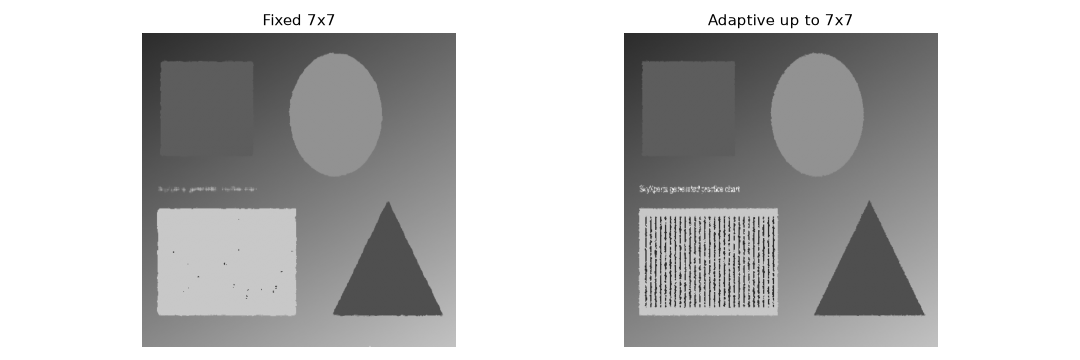

In [17]:
# This 512x512 image is larger than the Task 13 teaching sample.
large_clean = cv.cvtColor(cv.resize(img, (512, 512)), cv.COLOR_BGR2GRAY)
large_noisy = add_salt_pepper_noise(large_clean, density=0.30, seed=101)

def measure(function, image, repeats=3):
    function(image)  # Warm up; exclude plot/loading time from measurement.
    times = []
    for _ in range(repeats):
        start = perf_counter()
        result = function(image)
        times.append(perf_counter() - start)
    return float(np.median(times)), result

fixed_seconds, fixed_result = measure(lambda a: cv.medianBlur(a, 7), large_noisy)
adaptive_seconds, adaptive_result = measure(lambda a: adaptive_median_filter(a, 7), large_noisy)

def mean_absolute_error(reference, result):
    return float(np.mean(np.abs(reference.astype(np.float32) - result.astype(np.float32))))

print('Input:', large_noisy.shape, 'dtype:', large_noisy.dtype)
print(f'OpenCV fixed 7x7: {fixed_seconds:.6f} seconds')
print(f'Python adaptive up to 7x7: {adaptive_seconds:.6f} seconds')
print('Fixed MAE:', mean_absolute_error(large_clean, fixed_result))
print('Adaptive MAE:', mean_absolute_error(large_clean, adaptive_result))

show_images([('Fixed 7x7', fixed_result), ('Adaptive up to 7x7', adaptive_result)])


**Step 1:** Use the same image, dtype and noise realization for both algorithms.
Both use replicated borders and a maximum/window size of seven, but the adaptive
method may choose three or five locally.
**Step 2:** Warm up, measure three runs with a monotonic high-resolution timer,
and report their median. Do not include plotting or file reading in filter time.
**Step 3:** Compare quality with a clean reference, not just speed. MAE is average
absolute pixel error; lower is closer in this measure, not universally better-looking.

**Discussion to adapt to your measured results:** OpenCV's fixed filter runs in
optimized native code, while this adaptive example uses Python per-pixel loops.
The timing therefore measures these implementations; it does not establish an
intrinsic speed ratio between the two algorithms. Adaptive median can be useful
when impulse density varies spatially: small windows preserve more detail where
possible, larger ones help where noise is dense. It may still damage valid extremes
or fail at high density, and it need not outperform fixed median on every image.

For a stronger experiment repeat at densities 0.05, 0.30 and 0.60 over several seeds,
keep parameters explicit, and examine edges along with numerical error.


## References

[Course source](https://github.com/ffathy-tdx/SkyXperts-Vision-Course)

[OpenCV color spaces](https://docs.opencv.org/4.x/df/d9d/tutorial_py_colorspaces.html)

[OpenCV filtering](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html)

[OpenCV video](https://docs.opencv.org/4.x/dd/d43/tutorial_py_video_display.html)
